# 03 · Run the HotpotQA test-time-scaling experiments on a Colab GPU

Runs the AgentTTS HotpotQA pipeline (retrieve → merge → answer → fuse, prompts copied from `archon_hotpotqa.py`) with
**Qwen2.5-3B-Instruct as the retriever** and **Llama-3.2-3B-Instruct as the answerer**, over a grid of sample counts, and logs
effectiveness *and* resources for every configuration into a time-stamped folder in Drive:

```
0_Small_Big_Model_Switching/runs/<EXPERIMENT>/<YYYYmmdd-HHMMSS>_<GPU>_<split><n>/
  config.json  env.txt  code/tts_runner.py
  logs/        01_retrieve.log  02_qa.log  03_analyze.log  04_timed_retrieve.log  05_timed_qa.log
               stage_times.json (wall-clock seconds of every notebook step)
  retrieval/   every retrieval sample (text + token counts)
  qa/          every QA sample, every fused answer, one row per question × configuration
  stages/      measured seconds, FLOPs, peak VRAM, GPU utilisation per stage
  timed/       timed check: per-question latency of each chosen config (retrieval, merge, QA, fuser)
  results/     ret_then_gen_hotpotqa_lookup.csv (same columns as the repo's CSV_files, usable as the agent's Environment)
               results_with_costs.csv  per_question.csv  summary.md
               timed_latency.csv  timed_per_question.csv  timed_configs.json
  plots/       pareto_em_vs_flops.png  scaling_curves.png  compute_breakdown.png  latency_vs_em.png
```

**Runtime:** *Runtime → Change runtime type → L4 GPU* (recommended on Colab Pro: 24 GB, bf16, cheaper per hour than A100).
Each stage runs in its own process so GPU memory is fully released between models.

**How it stays fast:** each stage samples once at the largest count in the grid; smaller counts are scored on nested subsets of the same samples (the repo's `--merge_existing` idea). Results are written to Drive in chunks, so if Colab disconnects, re-running the same cells resumes where it stopped (set `RESUME_RUN_DIR`).

**Two kinds of time are recorded:**
- *Throughput cost* for every configuration in the grid (`est_gpu_s`): cheap to get, good for ranking, but not latency.
- *Measured latency* from the **timed check** (Stage 4): the best, recommended and Pareto-frontier configurations are each run on their own, one question at a time, with a wall clock on every step. This is how long a user would wait per question.

**Workflow for dev → test (no training is involved; models are used as-is):**
1. `SPLIT = "dev"` → full grid on 50 questions + timed check on 20 → pick configurations.
2. `SPLIT = "test"`, `CONFIGS_FROM_DEV_RUN = "<that dev run folder>"` → only the configurations chosen on dev are scored on the 500 unseen test questions, and the same configurations are timed on 50 test questions.

In [1]:
# ==== experiment settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "agenttts_hotpotqa"   # runs are grouped under runs/<EXPERIMENT>/ - rename per idea you try

SPLIT      = "dev"     # "dev" = 50-question search split (fast) | "test" = 500-question test split
N_EXAMPLES = 50        # dev: up to 100 | test: up to 500

RET_MODEL = {"dir": "Qwen2.5-3B-Instruct",   "id": "Qwen/Qwen2.5-3B-Instruct",         "params": 3.09e9, "nominal": 3e9}
QA_MODEL  = {"dir": "Llama-3.2-3B-Instruct", "id": "meta-llama/Llama-3.2-3B-Instruct", "params": 3.21e9, "nominal": 3e9}

RET_GRID = [1, 3, 5]        # retrieval samples to score (sampled once at max)
QA_GRID  = [1, 5, 10, 20]   # QA samples to score (add 40 to match the paper's best config; slower)

FUSER_QUERY = "full"   # "full" = repo behaviour: fuser prompt repeats the question + all candidate paragraphs (twice)
                       # "question" = fuser sees only the question -> far cheaper; a good idea to test
TOLERANCE   = 0.02     # "recommended" = cheapest config within this EM of the best
SEED        = 0
EXPECTED_GPU = "L4"

# ---- timed check: real speed, each chosen config run alone, one question at a time ----
RUN_TIMED_CHECK   = True
TIMED_N_QUESTIONS = {"dev": 20, "test": 50}   # questions timed per configuration
MAX_TIMED_CONFIGS = 4                         # best, recommended, then Pareto-frontier configs

# ---- test runs ----
CONFIGS_FROM_DEV_RUN = None   # SPLIT="test": folder of a finished dev run -> test (and time) only the configs chosen there

REUSE_RETRIEVAL_FROM = None   # e.g. f"{PROJECT_DIR}/runs/{EXPERIMENT}/20260926-160000_L4_dev50" to skip the retrieval stage
RESUME_RUN_DIR       = None   # set to an existing run folder to continue an interrupted run
DRY_RUN = False               # True = fake model outputs on CPU, to test the whole notebook in ~1 minute

In [2]:
import subprocess
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU. Runtime -> Change runtime type -> L4 GPU (or set DRY_RUN = True)."
    if EXPECTED_GPU not in gpu:
        print(f"⚠ Expected {EXPECTED_GPU}. The run will still work; the timings will differ.")
    if "T4" in gpu:
        print("⚠ T4 (15 GB, no bf16): set FUSER_QUERY = 'question' to keep prompts short enough.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]

GPU: Tesla T4, 15360 MiB, 7.5
⚠ Expected L4. The run will still work; the timings will differ.
⚠ T4 (15 GB, no bf16): set FUSER_QUERY = 'question' to keep prompts short enough.


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import os, json, shutil, platform
from datetime import datetime
from zoneinfo import ZoneInfo

DATA_FILE = f"{PROJECT_DIR}/data/hotpotqa/" + ("tts_test.json" if SPLIT == "dev" else "tts_test_2_samples500.json")
assert os.path.exists(DATA_FILE), "Data split not found - run notebook 01 first."

if RESUME_RUN_DIR:
    RUN_DIR = RESUME_RUN_DIR
else:
    stamp = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
    RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{stamp}_{GPU_TAG}_{SPLIT}{N_EXAMPLES}" + ("_dryrun" if DRY_RUN else "")
for sub in ["logs", "code", "retrieval", "qa", "stages", "results", "plots", "timed"]:
    os.makedirs(f"{RUN_DIR}/{sub}", exist_ok=True)

# configurations chosen on a dev run -> restrict the test grid to them
DEV_TIMED_CONFIGS = None
if SPLIT == "test":
    if CONFIGS_FROM_DEV_RUN:
        DEV_TIMED_CONFIGS = json.load(open(f"{CONFIGS_FROM_DEV_RUN}/results/timed_configs.json"))["configs"]
        RET_GRID = sorted({int(c.split(":")[0]) for c in DEV_TIMED_CONFIGS})
        QA_GRID  = sorted({int(c.split(":")[1]) for c in DEV_TIMED_CONFIGS})
        print("Configs chosen on dev (ret_k:qa_k):", DEV_TIMED_CONFIGS, "-> RET_GRID", RET_GRID, "QA_GRID", QA_GRID)
    else:
        print("⚠ Test run without CONFIGS_FROM_DEV_RUN: the whole grid will be run on", N_EXAMPLES, "questions (slow).")

# wall-clock of every notebook step, kept in logs/stage_times.json
TIMES_FILE = f"{RUN_DIR}/logs/stage_times.json"
TIMES = json.load(open(TIMES_FILE)) if os.path.exists(TIMES_FILE) else {}
def record_time(step, seconds):
    TIMES[step] = TIMES.get(step, 0.0) + seconds
    json.dump(TIMES, open(TIMES_FILE, "w"), indent=1)

config = dict(experiment=EXPERIMENT, split=SPLIT, n_examples=N_EXAMPLES, data_file=DATA_FILE, ret_model=RET_MODEL, qa_model=QA_MODEL,
              ret_grid=RET_GRID, qa_grid=QA_GRID, fuser_query=FUSER_QUERY, tolerance=TOLERANCE, seed=SEED,
              gpu=gpu, dry_run=DRY_RUN, reuse_retrieval_from=REUSE_RETRIEVAL_FROM,
              run_timed_check=RUN_TIMED_CHECK, timed_n_questions=TIMED_N_QUESTIONS, max_timed_configs=MAX_TIMED_CONFIGS,
              configs_from_dev_run=CONFIGS_FROM_DEV_RUN, dev_timed_configs=DEV_TIMED_CONFIGS,
              started=datetime.now(ZoneInfo("Asia/Singapore")).isoformat())
json.dump(config, open(f"{RUN_DIR}/config.json", "w"), indent=1)
print("Run folder:", RUN_DIR)

Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/agenttts_hotpotqa/20260927-095328_T4_dev50


### Install vLLM
It runs inside the stage subprocesses only, so no runtime restart is needed. Takes ~2–3 minutes.

In [5]:
import time, sys
_t = time.time()
if not DRY_RUN:
    !pip install -q vllm
    # vLLM installs its own PyTorch build; Colab's preinstalled torchaudio was built for a different CUDA
    # version and crashes on import ("PyTorch and TorchAudio were compiled with different CUDA versions").
    # Nothing here uses audio, so remove it.
    !pip uninstall -y -q torchaudio
    check = subprocess.run([sys.executable, "-c", "from vllm import LLM, SamplingParams; print('vLLM import OK')"],
                           capture_output=True, text=True)
    print(check.stdout or check.stderr[-2000:])
    assert check.returncode == 0, "vLLM does not import - see the error above (Runtime -> Disconnect and delete runtime, then run again)."
env = subprocess.run("nvidia-smi; echo; python -c 'import vllm, torch, transformers; "
                     "print(\"vllm\", vllm.__version__, \"| torch\", torch.__version__, torch.version.cuda, \"| transformers\", transformers.__version__)'",
                     shell=True, capture_output=True, text=True)
open(f"{RUN_DIR}/env.txt", "w").write(env.stdout + env.stderr + f"\npython {platform.python_version()}\n")
print(env.stdout[-400:] or env.stderr[-400:])
record_time("install_vllm", time.time() - _t)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.9/314.9 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.7/322.7 kB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 73.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6

### Copy the models from Drive to local disk (much faster loading)

In [6]:
_t = time.time()
LOCAL_MODELS = "/content/models"
for m in [RET_MODEL, QA_MODEL]:
    src, dst = f"{PROJECT_DIR}/models/{m['dir']}", f"{LOCAL_MODELS}/{m['dir']}"
    m["path"] = dst
    if DRY_RUN:
        continue
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run notebook 02 first."
    if not os.path.exists(f"{dst}/config.json"):
        print("copying", m["dir"], "...")
        shutil.copytree(src, dst, dirs_exist_ok=True)
record_time("copy_models_to_local_disk", time.time() - _t)
!du -sh {LOCAL_MODELS}/* 2>/dev/null

copying Qwen2.5-3B-Instruct ...
copying Llama-3.2-3B-Instruct ...
6.0G	/content/models/Llama-3.2-3B-Instruct
5.8G	/content/models/Qwen2.5-3B-Instruct


### The experiment runner
`tts_runner.py` holds the pipeline, metrics and cost accounting. It is saved into the run folder so every run keeps the exact code that produced it.

In [7]:
%%writefile /content/tts_runner.py
#!/usr/bin/env python
"""
tts_runner.py - AgentTTS HotpotQA "environment" runner for Google Colab.

Re-implements the retrieve -> merge -> generate -> fuse pipeline of
code_others/archon_hotpotqa.py (prompts copied verbatim from the repo), but:
  * runs the models with vLLM (much faster than the repo's HF generate loop),
  * samples each stage ONCE at the maximum sample count and scores every smaller
    sample count on nested subsets (same trick as the repo's --merge_existing mode),
  * records the resources used by every configuration (tokens, FLOPs, the paper's
    Eq. 4 budget, measured GPU seconds, peak VRAM),
  * writes a lookup table with the same columns as the repo's CSV_files/*.csv, so it
    can later serve as the Environment for the AgentTTS search agent.

Stages (each runs in its own process so GPU memory is fully released between them):
  python tts_runner.py retrieve --model_path ... --model_id ... --data ... --out_dir RUN
  python tts_runner.py qa       --model_path ... --model_id ... --retrieval_file ... --out_dir RUN
  python tts_runner.py analyze  --out_dir RUN
  python tts_runner.py timed_retrieve / timed_qa --configs 5:5,3:1 ...   (measured latency, batch size 1)

Use --backend mock to dry-run the whole pipeline on CPU without any model.
"""
import argparse
import json
import os
import random
import re
import string
import subprocess
import sys
import threading
import time
from collections import Counter

import numpy as np

# ----------------------------------------------------------------------------------
# Prompts: verbatim from code_others/archon_hotpotqa.py and archon/completions/components/prompts.py
# ----------------------------------------------------------------------------------
RET_SYSTEM = "You are a helpful assistant that return the beneficial references to the query."
QA_SYSTEM = "You are a helpful assistant."
FUSER_SYSTEM = "You are a helpful assistant who fuses multiple answers"


def build_query(example):
    """archon_hotpotqa.py main loop: 'Query: <q>References: \\n[1] ...\\n[2] ...'"""
    query = "Query: " + example["question"]
    query += "References: "
    for i, reference in enumerate(example["ctxs_candidate"]):
        query += f"\n[{i + 1}] " + reference
    return query


def retrieval_prompt(query_references):
    return (f"You have been provided with a query and a set of references. "
            f"Your task is to select references that comprehensively cover the information needed to answer the query. "
            f"Your response should include the original query and a list of selected references in the following format: 'Query: [query]\nSelected references: [reference number] [reference details]'."
            f"Here is the query and references: \n {query_references}.")


def qa_prompt(question, selected_references):
    query_references = "Query: " + question + "\nReferences:\n"
    for i, reference in enumerate(selected_references):
        query_references += f"[{i + 1}] " + reference + "\n"
    return (f"You will be provided with a set of references related to the query. "
            f"Your task is to answer the query using the provided references. If the references are insufficient, supplement your response with your own knowledge. "
            f"Here is the query and references: \n {query_references}.")


def fuser_prompt(query, responses):
    # make_fuser_prompt(critiques=None); the backslash line-continuations in the repo keep 12 spaces of indentation.
    pad = " " * 12
    prompt = (f"You have been provided with a set of responses from various open-source models to the latest user query, which is {query}."
              f"{pad}Your task is to synthesize these responses into a single, high-quality response. "
              f"{pad}It is crucial to critically evaluate the information provided in these responses, recognizing that some of it may be biased or incorrect. "
              f"{pad}Your response should not simply replicate the given answers but should offer a refined, accurate, and comprehensive reply to the instruction. "
              f"{pad}Ensure your response is well-structured, coherent, and adheres to the highest standards of accuracy and reliability.\n")
    prompt += f"Once again, the query is: {query}\n"
    prompt += "Responses from models:"
    for i, reference in enumerate(responses):
        prompt += f"\n{i + 1}. {reference}"
    return prompt


def merge(candidates):
    """Merge component of archon_hotpotqa.py: majority vote over [n] reference ids.
    Keeps the most common list length, then the most frequent ids. Returns 1-based ids."""
    ref_ids, lengths = [], []
    for candidate in candidates:
        numbers = re.findall(r"\[(\d+)\]", candidate)
        ref_ids.extend(numbers)
        lengths.append(len(numbers))
    if ref_ids:
        most_common_length = Counter(lengths).most_common()[0][0]
        selected = [e[0] for e in Counter(ref_ids).most_common()[0:most_common_length]]
    else:
        selected = ["1"]
    return [int(e) for e in selected]


# ----------------------------------------------------------------------------------
# Metrics. The repo imports utils.precision_recall_f1 / evaluation_2wiki.metric_evaluation,
# which are NOT in the public repo, so these are reconstructions (documented in summary.md).
# ----------------------------------------------------------------------------------
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())


def gen_metrics(response, gold):
    pred, ref = normalize_answer(response), normalize_answer(gold)
    em_strict = float(pred == ref)
    # "cover" EM: the normalized gold answer appears as a whole phrase in the normalized response
    em = float(bool(ref) and re.search(r"(^| )" + re.escape(ref) + r"( |$)", pred) is not None)
    p_tok, g_tok = pred.split(), ref.split()
    common = Counter(p_tok) & Counter(g_tok)
    same = sum(common.values())
    if same == 0:
        f1 = precision = recall = 0.0
    else:
        precision, recall = same / len(p_tok), same / len(g_tok)
        f1 = 2 * precision * recall / (precision + recall)
    return {"Gen_EM": em, "Gen_EM_strict": em_strict, "Gen_F1": f1, "Gen_Precision": precision, "Gen_Recall": recall}


def ret_metrics(gt_ids, pred_ids):
    gt, pred = set(gt_ids), set(pred_ids)
    inter = len(gt & pred)
    p = inter / len(pred) if pred else 0.0
    r = inter / len(gt) if gt else 0.0
    f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
    return {"Ret_Precision": p, "Ret_Recall": r, "Ret_F1": f1, "Ret_ACC": float(gt <= pred)}


# ----------------------------------------------------------------------------------
# Paper budget (Eq. 4) - same code as AgentTTS.compute_budget
# ----------------------------------------------------------------------------------
def compute_budget(S, M_large, Np1, Nd1, M_small=3e9, Np2=128, Nd2=64):
    alpha = M_large / M_small
    beta1 = Np1 / Nd1
    beta2 = Np2 / Nd2
    beta3 = Np1 / Np2
    return beta2 * ((alpha * beta3 / beta1) * (beta1 + S) - 1)


def budget_from_tokens(M, prompt_tokens, total_output_tokens, M_small=3e9, Np2=128, Nd2=64):
    """Eq. 4 rewritten for measured tokens: M/M0*(Np + sum Nd)/Nd2 - Np2/Nd2 (identical to Eq. 4 when sum Nd = S*Nd)."""
    return (M / M_small) * (prompt_tokens + total_output_tokens) / Nd2 - Np2 / Nd2


# ----------------------------------------------------------------------------------
# GPU monitor (nvidia-smi polling, works for vLLM's separate engine process)
# ----------------------------------------------------------------------------------
class GPUMonitor:
    def __init__(self, interval=1.0):
        self.interval, self.mem, self.util, self._stop = interval, [], [], threading.Event()
        self.ok = subprocess.run(["which", "nvidia-smi"], capture_output=True).returncode == 0

    def _loop(self):
        while not self._stop.is_set():
            try:
                out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used,utilization.gpu",
                                      "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=5).stdout
                m, u = out.strip().splitlines()[0].split(",")
                self.mem.append(float(m))
                self.util.append(float(u))
            except Exception:
                pass
            self._stop.wait(self.interval)

    def __enter__(self):
        if self.ok:
            self.t = threading.Thread(target=self._loop, daemon=True)
            self.t.start()
        return self

    def __exit__(self, *a):
        self._stop.set()

    def summary(self):
        return {"peak_vram_mb": max(self.mem) if self.mem else None,
                "mean_gpu_util_pct": float(np.mean(self.util)) if self.util else None}


def gpu_name():
    try:
        return subprocess.run(["nvidia-smi", "--query-gpu=name,compute_cap", "--format=csv,noheader"],
                              capture_output=True, text=True).stdout.strip().splitlines()[0]
    except Exception:
        return "none"


# ----------------------------------------------------------------------------------
# Backends
# ----------------------------------------------------------------------------------
class VLLMBackend:
    def __init__(self, model_path, max_model_len, gpu_memory_utilization, seed, prefix_caching=True):
        from vllm import LLM
        cap = gpu_name().split(",")[-1].strip()
        dtype = "half" if cap and cap[0].isdigit() and float(cap) < 8.0 else "auto"  # T4/V100: no bf16
        self.llm = LLM(model=model_path, max_model_len=max_model_len, dtype=dtype,
                       gpu_memory_utilization=gpu_memory_utilization, enable_prefix_caching=prefix_caching, seed=seed)
        self.tok = self.llm.get_tokenizer()
        self.max_model_len = max_model_len

    def encode(self, system, user):
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        text = self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        return list(self.tok(text, add_special_tokens=False)["input_ids"])  # template already holds BOS

    def generate(self, token_prompts, n, temperature, max_tokens, seeds, meta=None):
        from vllm import SamplingParams
        sps = [SamplingParams(n=n, temperature=temperature, max_tokens=max_tokens, seed=s) for s in seeds]
        prompts = [{"prompt_token_ids": ids} for ids in token_prompts]
        outs = self.llm.generate(prompts, sps, use_tqdm=False)
        return [[(c.text, len(c.token_ids)) for c in o.outputs] for o in outs]


class MockBackend:
    """CPU stand-in so the full pipeline (files, metrics, costs, plots) can be tested without a GPU."""

    def __init__(self, *a, **k):
        self.max_model_len = k.get("max_model_len", 10 ** 9)

    def encode(self, system, user):
        return (system + " " + user).split()  # "tokens" = words

    def generate(self, token_prompts, n, temperature, max_tokens, seeds, meta=None):
        res = []
        for ids, s, m in zip(token_prompts, seeds, meta):
            rng = random.Random(s)
            outs = []
            for _ in range(n):
                if m["kind"] == "ret":
                    sel = [g + 1 for g in m["gt"] if rng.random() < 0.6] + [rng.randint(1, m["n_refs"]) for _ in range(rng.randint(1, 2))]
                    text = f"Query: {m['q']}\nSelected references: " + ", ".join(f"[{i}] ..." for i in sel)
                elif m["kind"] == "qa":
                    text = f"Based on the references, the answer is {m['gold']}." if rng.random() < m["p"] else "The answer is unclear."
                else:
                    text = f"The answer is {m['gold']}." if rng.random() < m["p"] else "It is unclear."
                outs.append((text, len(text.split()) + rng.randint(5, 40)))
            res.append(outs)
            time.sleep(0.001 * n)
        return res


def make_backend(args, prefix_caching=True):
    if args.backend == "mock":
        return MockBackend(max_model_len=args.max_model_len)
    return VLLMBackend(args.model_path, args.max_model_len, args.gpu_memory_utilization, args.seed, prefix_caching)


def slug(model_id):
    return model_id.split("/")[-1]


def read_jsonl(path):
    if not os.path.exists(path):
        return []
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]


def load_examples(path, n):
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    return data[:n] if n and n > 0 else data


def log(*a):
    print(time.strftime("[%H:%M:%S]"), *a, flush=True)


# ----------------------------------------------------------------------------------
# Stage 1: retrieval
# ----------------------------------------------------------------------------------
def stage_retrieve(args):
    os.makedirs(os.path.join(args.out_dir, "retrieval"), exist_ok=True)
    os.makedirs(os.path.join(args.out_dir, "stages"), exist_ok=True)
    out_path = os.path.join(args.out_dir, "retrieval", f"{slug(args.model_id)}.jsonl")
    examples = load_examples(args.data, args.n_examples)
    done = {r["idx"] for r in read_jsonl(out_path)}
    todo = [i for i in range(len(examples)) if i not in done]
    log(f"retrieval | model={args.model_id} | questions={len(examples)} (already done {len(done)}) | samples={args.max_samples}")
    if not todo:
        log("nothing to do")
        return

    t0 = time.time()
    with GPUMonitor() as mon:
        be = make_backend(args)
        load_s = time.time() - t0
        t1 = time.time()
        stage_flops = 0.0
        n_prompt = n_out = 0
        for c in range(0, len(todo), args.chunk):
            idxs = todo[c:c + args.chunk]
            prompts, meta = [], []
            for i in idxs:
                ex = examples[i]
                prompts.append(be.encode(RET_SYSTEM, retrieval_prompt(build_query(ex))))
                meta.append({"kind": "ret", "gt": ex["ret_answers"], "n_refs": len(ex["ctxs_candidate"]), "q": ex["question"]})
            too_long = [len(p) + args.max_tokens > be.max_model_len for p in prompts]
            if any(too_long):
                raise SystemExit(f"retrieval prompt longer than max_model_len={be.max_model_len}; raise --max_model_len or rebuild data with fewer candidates")
            outs = be.generate(prompts, args.max_samples, args.temperature, args.max_tokens,
                               seeds=[args.seed * 100003 + i for i in idxs], meta=meta)
            with open(out_path, "a", encoding="utf-8") as f:
                for i, p, o in zip(idxs, prompts, outs):
                    ex = examples[i]
                    rec = {"idx": i, "question": ex["question"], "answer": ex["answer"], "gt_ids": ex["ret_answers"],
                           "model_id": args.model_id, "params": args.params, "nominal_params": args.nominal_params,
                           "prompt_tokens": len(p), "samples": [{"text": t, "out_tokens": k} for t, k in o]}
                    f.write(json.dumps(rec, ensure_ascii=False) + "\n")
                    n_prompt += len(p)
                    n_out += sum(k for _, k in o)
                    stage_flops += 2 * args.params * (len(p) + sum(k for _, k in o))
            log(f"  retrieval {min(c + args.chunk, len(todo))}/{len(todo)} questions")
        gen_s = time.time() - t1
    stats = {"stage": "retrieve", "model_id": args.model_id, "gpu": gpu_name(), "questions": len(todo),
             "samples_per_question": args.max_samples, "load_s": load_s, "gen_s": gen_s,
             "prompt_tokens": n_prompt, "output_tokens": n_out, "flops": stage_flops,
             "sec_per_flop": gen_s / stage_flops if stage_flops else None, **mon.summary()}
    with open(os.path.join(args.out_dir, "stages", f"retrieve__{slug(args.model_id)}__{int(time.time())}.json"), "w") as f:
        json.dump(stats, f, indent=1)
    log(f"retrieval done in {gen_s:.0f}s (+{load_s:.0f}s load) | peak VRAM {stats['peak_vram_mb']} MB")


# ----------------------------------------------------------------------------------
# Stage 2: merge -> QA sampling -> fuser, for every (ret_k, qa_k) in the grid
# ----------------------------------------------------------------------------------
def stage_qa(args):
    ret_grid = sorted({int(x) for x in args.ret_grid.split(",")})
    qa_grid = sorted({int(x) for x in args.qa_grid.split(",")})
    qa_max = max(qa_grid)
    os.makedirs(os.path.join(args.out_dir, "qa"), exist_ok=True)
    os.makedirs(os.path.join(args.out_dir, "stages"), exist_ok=True)

    ret_rows = sorted(read_jsonl(args.retrieval_file), key=lambda r: r["idx"])
    if args.n_examples and args.n_examples > 0:
        ret_rows = [r for r in ret_rows if r["idx"] < args.n_examples]
    examples = load_examples(args.data, 0)
    n_ret_samples = min(len(r["samples"]) for r in ret_rows)
    if max(ret_grid) > n_ret_samples:
        raise SystemExit(f"ret_grid max {max(ret_grid)} > retrieval samples available ({n_ret_samples})")

    ret_model = ret_rows[0]["model_id"]
    tag = f"{slug(ret_model)}__{slug(args.model_id)}"
    rows_path = os.path.join(args.out_dir, "qa", f"{tag}.jsonl")
    samples_path = os.path.join(args.out_dir, "qa", f"{tag}__qa_samples.jsonl")
    n_cfg = len(ret_grid) * len(qa_grid)
    per_q = Counter(r["idx"] for r in read_jsonl(rows_path))
    todo = [r for r in ret_rows if per_q.get(r["idx"], 0) < n_cfg]
    log(f"qa | retriever={ret_model} | qa model={args.model_id} | questions={len(ret_rows)} (todo {len(todo)}) | "
        f"ret_grid={ret_grid} qa_grid={qa_grid} | fuser_query={args.fuser_query}")
    if not todo:
        log("nothing to do")
        return
    # drop partial rows of unfinished questions so they are recomputed cleanly
    if os.path.exists(rows_path):
        keep = [r for r in read_jsonl(rows_path) if per_q[r["idx"]] >= n_cfg]
        with open(rows_path, "w", encoding="utf-8") as f:
            for r in keep:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")

    t0 = time.time()
    qa_flops = fuse_flops = 0.0
    n_truncated = 0
    with GPUMonitor() as mon:
        be = make_backend(args)
        load_s = time.time() - t0
        t1 = time.time()
        for c in range(0, len(todo), args.chunk):
            chunk = todo[c:c + args.chunk]
            # --- merge + unique QA prompts
            plan = []  # (row, ret_k, selected_ids)
            uniq = {}  # (idx, tuple(sel)) -> position
            qa_prompts, qa_meta, qa_keys = [], [], []
            for r in chunk:
                ex = examples[r["idx"]]
                texts = [s["text"] for s in r["samples"]]
                for k in ret_grid:
                    sel = merge(texts[:k])
                    plan.append((r, k, sel))
                    key = (r["idx"], tuple(sel))
                    if key not in uniq:
                        refs = ex["ctxs_candidate"]
                        # selected references kept in original reference order (as the repo's loop does)
                        chosen = [refs[i - 1] for i in sorted(set(sel)) if 1 <= i <= len(refs)]
                        uniq[key] = len(qa_prompts)
                        qa_prompts.append(be.encode(QA_SYSTEM, qa_prompt(ex["question"], chosen)))
                        hit = len(set(i - 1 for i in sel) & set(ex["ret_answers"])) / max(1, len(ex["ret_answers"]))
                        qa_meta.append({"kind": "qa", "gold": ex["answer"], "p": 0.25 + 0.5 * hit})
                        qa_keys.append(key)
            qa_outs = be.generate(qa_prompts, qa_max, args.qa_temperature, args.qa_max_tokens,
                                  seeds=[args.seed * 7919 + hash(k) % 100000 for k in qa_keys], meta=qa_meta)
            with open(samples_path, "a", encoding="utf-8") as f:
                for key, p, o in zip(qa_keys, qa_prompts, qa_outs):
                    f.write(json.dumps({"idx": key[0], "selected_ids": list(key[1]), "prompt_tokens": len(p),
                                        "samples": [{"text": t, "out_tokens": k} for t, k in o]}, ensure_ascii=False) + "\n")
                    qa_flops += 2 * args.params * (len(p) + sum(k for _, k in o))

            # --- fuser prompts, one per unique (idx, selection, qa_k)
            fz_index, fz_prompts, fz_meta, fz_flags = {}, [], [], []
            for r, k, sel in plan:
                key = (r["idx"], tuple(sel))
                ex = examples[r["idx"]]
                outs = qa_outs[uniq[key]]
                for q in qa_grid:
                    fkey = key + (q,)
                    if fkey in fz_index:
                        continue
                    responses = [t for t, _ in outs[:q]]
                    full_query = build_query(ex)
                    query = full_query if args.fuser_query == "full" else "Query: " + ex["question"]
                    ids = be.encode(FUSER_SYSTEM, fuser_prompt(query, responses))
                    truncated = False
                    if len(ids) + args.fuser_max_tokens > be.max_model_len:
                        ids = be.encode(FUSER_SYSTEM, fuser_prompt("Query: " + ex["question"], responses))
                        truncated = True
                        n_truncated += 1
                    hit = sum(normalize_answer(ex["answer"]) in normalize_answer(t) for t in responses) / len(responses)
                    fz_index[fkey] = len(fz_prompts)
                    fz_prompts.append(ids)
                    fz_meta.append({"kind": "fuse", "gold": ex["answer"], "p": 0.1 + 0.85 * hit})
                    fz_flags.append(truncated)
            fz_outs = be.generate(fz_prompts, 1, args.fuser_temperature, args.fuser_max_tokens,
                                  seeds=[args.seed * 104729 + i for i in range(len(fz_prompts))], meta=fz_meta)

            # --- rows: one per (question, ret_k, qa_k)
            with open(rows_path, "a", encoding="utf-8") as f:
                for r, k, sel in plan:
                    key = (r["idx"], tuple(sel))
                    outs = qa_outs[uniq[key]]
                    qa_p = len(qa_prompts[uniq[key]])
                    rm = ret_metrics(r["gt_ids"], [i - 1 for i in sel])
                    for q in qa_grid:
                        j = fz_index[key + (q,)]
                        text, fz_out = fz_outs[j][0]
                        row = {
                            "idx": r["idx"], "question": r["question"], "gold": r["answer"],
                            "retrieve_model_name": ret_model, "retrieve_samples": k,
                            "generate_model_name": args.model_id, "generate_samples": q,
                            "ret_params": r["params"], "ret_nominal_params": r["nominal_params"],
                            "qa_params": args.params, "qa_nominal_params": args.nominal_params,
                            "selected_ids": [i - 1 for i in sel], "gt_ids": r["gt_ids"],
                            "ret_prompt_tokens": r["prompt_tokens"],
                            "ret_output_tokens": sum(s["out_tokens"] for s in r["samples"][:k]),
                            "qa_prompt_tokens": qa_p,
                            "qa_output_tokens": sum(n for _, n in outs[:q]),
                            "fuse_prompt_tokens": len(fz_prompts[j]), "fuse_output_tokens": fz_out,
                            "fuser_query_truncated": fz_flags[j],
                            "response": text, **rm, **gen_metrics(text, r["answer"]),
                        }
                        f.write(json.dumps(row, ensure_ascii=False) + "\n")
                    # fuser flops counted once per unique prompt below
            for j, (ids, o) in enumerate(zip(fz_prompts, fz_outs)):
                fuse_flops += 2 * args.params * (len(ids) + o[0][1])
            log(f"  qa {min(c + args.chunk, len(todo))}/{len(todo)} questions | fuser prompts this chunk {len(fz_prompts)}")
        gen_s = time.time() - t1
    stats = {"stage": "qa", "model_id": args.model_id, "retriever": ret_model, "gpu": gpu_name(), "questions": len(todo),
             "qa_samples_per_prompt": qa_max, "load_s": load_s, "gen_s": gen_s, "flops": qa_flops + fuse_flops,
             "qa_flops": qa_flops, "fuse_flops": fuse_flops, "fuser_prompts_truncated": n_truncated,
             "sec_per_flop": gen_s / (qa_flops + fuse_flops) if qa_flops + fuse_flops else None, **mon.summary()}
    with open(os.path.join(args.out_dir, "stages", f"qa__{tag}__{int(time.time())}.json"), "w") as f:
        json.dump(stats, f, indent=1)
    log(f"qa done in {gen_s:.0f}s (+{load_s:.0f}s load) | peak VRAM {stats['peak_vram_mb']} MB | truncated fuser prompts: {n_truncated}")


# ----------------------------------------------------------------------------------
# Timed check: run chosen configurations one question at a time (batch size 1) and
# measure real end-to-end latency. Prefix caching is OFF so no request reuses another's work.
# Two processes (one per model) - latency = retrieval + merge + QA sampling + fusion.
# ----------------------------------------------------------------------------------
def parse_configs(text):
    return [tuple(int(x) for x in c.split(":")) for c in text.split(",") if c.strip()]


def selected_references(ex, sel):
    refs = ex["ctxs_candidate"]
    return [refs[i - 1] for i in sorted(set(sel)) if 1 <= i <= len(refs)]


def _warmup(be, args):
    ids = be.encode("You are a helpful assistant.", "Say hello.")
    be.generate([ids], 1, 0.0, 8, seeds=[0], meta=[{"kind": "qa", "gold": "hello", "p": 1.0}])


def stage_timed_retrieve(args):
    configs = parse_configs(args.configs)
    ret_ks = sorted({k for k, _ in configs})
    os.makedirs(os.path.join(args.out_dir, "timed"), exist_ok=True)
    out_path = os.path.join(args.out_dir, "timed", "retrieval.jsonl")
    examples = load_examples(args.data, args.n_examples)
    done = {(r["idx"], r["ret_k"]) for r in read_jsonl(out_path)}
    log(f"timed retrieval | model={args.model_id} | questions={len(examples)} | ret_k={ret_ks} | batch size 1, prefix cache off")
    t0 = time.time()
    with GPUMonitor() as mon:
        be = make_backend(args, prefix_caching=False)
        load_s = time.time() - t0
        _warmup(be, args)
        t1 = time.time()
        for i, ex in enumerate(examples):
            for k in ret_ks:
                if (i, k) in done:
                    continue
                ts = time.perf_counter()
                ids = be.encode(RET_SYSTEM, retrieval_prompt(build_query(ex)))
                out = be.generate([ids], k, args.temperature, args.max_tokens, seeds=[args.seed * 100003 + i],
                                  meta=[{"kind": "ret", "gt": ex["ret_answers"], "n_refs": len(ex["ctxs_candidate"]), "q": ex["question"]}])[0]
                lat = time.perf_counter() - ts
                with open(out_path, "a", encoding="utf-8") as f:
                    f.write(json.dumps({"idx": i, "ret_k": k, "model_id": args.model_id, "latency_s": lat, "prompt_tokens": len(ids),
                                        "output_tokens": sum(n for _, n in out), "texts": [t for t, _ in out]},
                                       ensure_ascii=False) + "\n")
            if (i + 1) % 5 == 0 or i + 1 == len(examples):
                log(f"  timed retrieval {i + 1}/{len(examples)} questions")
        total_s = time.time() - t1
    with open(os.path.join(args.out_dir, "stages", f"timed_retrieve__{int(time.time())}.json"), "w") as f:
        json.dump({"stage": "timed_retrieve", "model_id": args.model_id, "gpu": gpu_name(), "load_s": load_s,
                   "wall_s": total_s, **mon.summary()}, f, indent=1)
    log(f"timed retrieval done in {total_s:.0f}s (+{load_s:.0f}s load)")


def stage_timed_qa(args):
    configs = parse_configs(args.configs)
    out_path = os.path.join(args.out_dir, "timed", "qa.jsonl")
    examples = load_examples(args.data, args.n_examples)
    ret = {(r["idx"], r["ret_k"]): r for r in read_jsonl(os.path.join(args.out_dir, "timed", "retrieval.jsonl"))}
    done = {(r["idx"], r["retrieve_samples"], r["generate_samples"]) for r in read_jsonl(out_path)}
    log(f"timed qa | model={args.model_id} | questions={len(examples)} | configs={configs} | batch size 1, prefix cache off")
    t0 = time.time()
    with GPUMonitor() as mon:
        be = make_backend(args, prefix_caching=False)
        load_s = time.time() - t0
        _warmup(be, args)
        t1 = time.time()
        for i, ex in enumerate(examples):
            for rk, qk in configs:
                if (i, rk, qk) in done or (i, rk) not in ret:
                    continue
                r = ret[(i, rk)]
                ts = time.perf_counter()
                sel = merge(r["texts"])
                chosen = selected_references(ex, sel)
                t_merge = time.perf_counter() - ts
                ts = time.perf_counter()
                q_ids = be.encode(QA_SYSTEM, qa_prompt(ex["question"], chosen))
                hit = len(set(j - 1 for j in sel) & set(ex["ret_answers"])) / max(1, len(ex["ret_answers"]))
                outs = be.generate([q_ids], qk, args.qa_temperature, args.qa_max_tokens, seeds=[args.seed * 7919 + i],
                                   meta=[{"kind": "qa", "gold": ex["answer"], "p": 0.25 + 0.5 * hit}])[0]
                t_qa = time.perf_counter() - ts
                ts = time.perf_counter()
                responses = [t for t, _ in outs]
                query = build_query(ex) if args.fuser_query == "full" else "Query: " + ex["question"]
                f_ids = be.encode(FUSER_SYSTEM, fuser_prompt(query, responses))
                if len(f_ids) + args.fuser_max_tokens > be.max_model_len:
                    f_ids = be.encode(FUSER_SYSTEM, fuser_prompt("Query: " + ex["question"], responses))
                fh = sum(normalize_answer(ex["answer"]) in normalize_answer(t) for t in responses) / len(responses)
                text, f_out = be.generate([f_ids], 1, args.fuser_temperature, args.fuser_max_tokens, seeds=[args.seed * 104729 + i],
                                          meta=[{"kind": "fuse", "gold": ex["answer"], "p": 0.1 + 0.85 * fh}])[0][0]
                t_fuse = time.perf_counter() - ts
                row = {"idx": i, "retrieve_model_name": r["model_id"], "retrieve_samples": rk,
                       "generate_model_name": args.model_id, "generate_samples": qk,
                       "latency_retrieval_s": r["latency_s"], "latency_merge_s": t_merge, "latency_qa_s": t_qa,
                       "latency_fuser_s": t_fuse,
                       "latency_total_s": r["latency_s"] + t_merge + t_qa + t_fuse,
                       "ret_prompt_tokens": r["prompt_tokens"], "ret_output_tokens": r["output_tokens"],
                       "qa_prompt_tokens": len(q_ids), "qa_output_tokens": sum(n for _, n in outs),
                       "fuse_prompt_tokens": len(f_ids), "fuse_output_tokens": f_out, "response": text,
                       **ret_metrics(ex["ret_answers"], [j - 1 for j in sel]), **gen_metrics(text, ex["answer"])}
                with open(out_path, "a", encoding="utf-8") as f:
                    f.write(json.dumps(row, ensure_ascii=False) + "\n")
            if (i + 1) % 5 == 0 or i + 1 == len(examples):
                log(f"  timed qa {i + 1}/{len(examples)} questions")
        total_s = time.time() - t1
    with open(os.path.join(args.out_dir, "stages", f"timed_qa__{int(time.time())}.json"), "w") as f:
        json.dump({"stage": "timed_qa", "model_id": args.model_id, "gpu": gpu_name(), "load_s": load_s,
                   "wall_s": total_s, **mon.summary()}, f, indent=1)
    log(f"timed qa done in {total_s:.0f}s (+{load_s:.0f}s load)")


# ----------------------------------------------------------------------------------
# Stage 3: analysis - lookup table, costs, Pareto frontier, plots, summary
# ----------------------------------------------------------------------------------
# Reference palette (dataviz skill, light mode): categorical slots in fixed order + text/grid inks.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"


def pareto_front(costs, scores):
    order = np.lexsort((-np.asarray(scores), np.asarray(costs)))  # cost asc, score desc
    front, best = [], -np.inf
    for i in order:
        if scores[i] > best + 1e-12:
            front.append(i)
            best = scores[i]
    return front


def stage_analyze(args):
    import pandas as pd
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    run = args.out_dir
    rows = []
    for fn in sorted(os.listdir(os.path.join(run, "qa"))):
        if fn.endswith(".jsonl") and not fn.endswith("__qa_samples.jsonl"):
            rows += read_jsonl(os.path.join(run, "qa", fn))
    if not rows:
        raise SystemExit("no QA rows found - run the qa stage first")
    df = pd.DataFrame(rows)
    os.makedirs(os.path.join(run, "results"), exist_ok=True)
    os.makedirs(os.path.join(run, "plots"), exist_ok=True)

    # per-question costs
    df["flops_retrieval"] = 2 * df.ret_params * (df.ret_prompt_tokens + df.ret_output_tokens)
    df["flops_qa_sampling"] = 2 * df.qa_params * (df.qa_prompt_tokens + df.qa_output_tokens)
    df["flops_fuser"] = 2 * df.qa_params * (df.fuse_prompt_tokens + df.fuse_output_tokens)
    df["flops_total"] = df.flops_retrieval + df.flops_qa_sampling + df.flops_fuser
    df["budget_actual_ret"] = budget_from_tokens(df.ret_params, df.ret_prompt_tokens, df.ret_output_tokens)
    df["budget_actual_qa"] = budget_from_tokens(df.qa_params, df.qa_prompt_tokens, df.qa_output_tokens)
    df["budget_actual_fuser"] = budget_from_tokens(df.qa_params, df.fuse_prompt_tokens, df.fuse_output_tokens)

    # measured throughput -> estimated GPU seconds per configuration
    spf = {}
    for fn in os.listdir(os.path.join(run, "stages")):
        s = json.load(open(os.path.join(run, "stages", fn)))
        if s["stage"] not in ("retrieve", "qa"):
            continue
        key = (s["stage"], s["model_id"])
        a = spf.setdefault(key, {"gen_s": 0.0, "flops": 0.0, "peak": 0.0, "gpu": s.get("gpu")})
        a["gen_s"] += s["gen_s"]
        a["flops"] += s["flops"]
        a["peak"] = max(a["peak"], s.get("peak_vram_mb") or 0)
    def sec_per_flop(stage, model):
        a = spf.get((stage, model))
        return a["gen_s"] / a["flops"] if a and a["flops"] else np.nan
    df["est_gpu_s"] = (df.flops_retrieval * df.retrieve_model_name.map(lambda m: sec_per_flop("retrieve", m))
                       + (df.flops_qa_sampling + df.flops_fuser) * df.generate_model_name.map(lambda m: sec_per_flop("qa", m)))

    keys = ["retrieve_model_name", "retrieve_samples", "generate_model_name", "generate_samples"]
    metric_cols = ["Gen_EM", "Gen_EM_strict", "Gen_F1", "Gen_Precision", "Gen_Recall",
                   "Ret_ACC", "Ret_F1", "Ret_Precision", "Ret_Recall"]
    cost_cols = ["ret_prompt_tokens", "ret_output_tokens", "qa_prompt_tokens", "qa_output_tokens",
                 "fuse_prompt_tokens", "fuse_output_tokens", "flops_retrieval", "flops_qa_sampling", "flops_fuser",
                 "flops_total", "budget_actual_ret", "budget_actual_qa", "budget_actual_fuser", "est_gpu_s"]
    g = df.groupby(keys)
    tab = g[metric_cols + cost_cols].mean().reset_index()
    tab.insert(0, "examples", g.size().values)
    tab["fuser_truncated_frac"] = g["fuser_query_truncated"].mean().values
    first = g[["ret_nominal_params", "qa_nominal_params"]].first().reset_index(drop=True)
    tab["budget_eq4"] = [compute_budget(r.retrieve_samples, a, 2048, 128) + compute_budget(r.generate_samples, b, 256, 64)
                         for r, a, b in zip(tab.itertuples(), first.ret_nominal_params, first.qa_nominal_params)]
    tab["budget_actual_sampling"] = tab.budget_actual_ret + tab.budget_actual_qa
    tab["budget_actual_total"] = tab.budget_actual_sampling + tab.budget_actual_fuser
    tab["fuser_share_of_flops"] = tab.flops_fuser / tab.flops_total
    tab["peak_vram_mb"] = [max(spf.get(("retrieve", r), {}).get("peak", 0), spf.get(("qa", q), {}).get("peak", 0))
                           for r, q in zip(tab.retrieve_model_name, tab.generate_model_name)]
    tab["config"] = [f"{slug(a)}×{b} → {slug(c)}×{d}" for a, b, c, d in
                     zip(tab.retrieve_model_name, tab.retrieve_samples, tab.generate_model_name, tab.generate_samples)]
    tab["label"] = [f"R{b}/Q{d}" for b, d in zip(tab.retrieve_samples, tab.generate_samples)]

    # frontier + picks
    front = pareto_front(tab.flops_total.values, tab.Gen_EM.values)
    tab["on_pareto_front"] = False
    tab.loc[tab.index[front], "on_pareto_front"] = True
    best_em = tab.Gen_EM.max()
    best = tab[tab.Gen_EM == best_em].sort_values("flops_total").iloc[0]
    within = tab[tab.Gen_EM >= best_em - args.tolerance].sort_values("flops_total")
    rec = within.iloc[0]
    tab = tab.sort_values(["Gen_EM", "flops_total"], ascending=[False, True])

    # configurations to time one question at a time: best, recommended, then Pareto points by EM
    pick = [best, rec] + [r for _, r in tab[tab.on_pareto_front].sort_values("Gen_EM", ascending=False).iterrows()]
    timed_cfgs = []
    for r in pick:
        c = f"{int(r.retrieve_samples)}:{int(r.generate_samples)}"
        if c not in timed_cfgs:
            timed_cfgs.append(c)
    timed_cfgs = timed_cfgs[:args.max_timed]
    source = "picked on this run"
    if args.fixed_configs:  # test run: keep the configurations chosen on the dev run
        timed_cfgs, source = [c.strip() for c in args.fixed_configs.split(",") if c.strip()], "chosen on the dev run"
    with open(os.path.join(run, "results", "timed_configs.json"), "w") as f:
        json.dump({"configs": timed_cfgs, "configs_source": source,
                   "best_on_this_run": f"{int(best.retrieve_samples)}:{int(best.generate_samples)}",
                   "recommended_on_this_run": f"{int(rec.retrieve_samples)}:{int(rec.generate_samples)}"}, f, indent=1)

    # measured latency (timed check), if it has been run
    timed = None
    tpath = os.path.join(run, "timed", "qa.jsonl")
    lat_cols = ["latency_retrieval_s", "latency_merge_s", "latency_qa_s", "latency_fuser_s", "latency_total_s"]
    if os.path.exists(tpath) and read_jsonl(tpath):
        td = pd.DataFrame(read_jsonl(tpath))
        td.to_csv(os.path.join(run, "results", "timed_per_question.csv"), index=False)
        tg = td.groupby(keys)
        timed = tg[lat_cols + ["Gen_EM", "Ret_F1"]].mean().reset_index()
        timed.insert(4, "timed_questions", tg.size().values)
        timed["latency_p50_s"] = tg.latency_total_s.median().values
        timed["latency_p95_s"] = tg.latency_total_s.quantile(0.95).values
        timed["latency_min_s"] = tg.latency_total_s.min().values
        timed["latency_max_s"] = tg.latency_total_s.max().values
        timed["questions_per_min"] = 60.0 / timed.latency_total_s
        timed = timed.rename(columns={"latency_total_s": "latency_mean_s", "Gen_EM": "Gen_EM_timed_subset",
                                      "Ret_F1": "Ret_F1_timed_subset"})
        timed["label"] = [f"R{b}/Q{d}" for b, d in zip(timed.retrieve_samples, timed.generate_samples)]
        timed.to_csv(os.path.join(run, "results", "timed_latency.csv"), index=False)
        tab = tab.merge(timed[keys + ["latency_p50_s", "latency_p95_s", "questions_per_min"]], on=keys, how="left")
        tab = tab.sort_values(["Gen_EM", "flops_total"], ascending=[False, True])
    else:
        for c in ["latency_p50_s", "latency_p95_s", "questions_per_min"]:
            tab[c] = np.nan

    repo_cols = ["examples", "generate_model_name", "generate_samples", "retrieve_model_name", "retrieve_samples",
                 "Gen_EM", "Gen_F1", "Gen_Precision", "Gen_Recall", "Ret_ACC", "Ret_F1", "Ret_Precision", "Ret_Recall"]
    tab[repo_cols].to_csv(os.path.join(run, "results", "ret_then_gen_hotpotqa_lookup.csv"), index=False)
    full_cols = ["config"] + repo_cols + ["Gen_EM_strict", "on_pareto_front", "budget_eq4", "budget_actual_sampling",
                                          "budget_actual_total", "flops_total", "flops_retrieval", "flops_qa_sampling",
                                          "flops_fuser", "fuser_share_of_flops", "est_gpu_s", "latency_p50_s", "latency_p95_s",
                                          "questions_per_min", "peak_vram_mb"] + \
                [c for c in cost_cols if c.endswith("tokens")] + ["fuser_truncated_frac"]
    tab[full_cols].to_csv(os.path.join(run, "results", "results_with_costs.csv"), index=False)
    df.to_csv(os.path.join(run, "results", "per_question.csv"), index=False)

    # ---------------- plots ----------------
    plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2,
                         "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                         "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.grid": True,
                         "grid.color": GRID, "grid.linewidth": 0.8})
    n = int(tab.examples.max())
    em_se = np.sqrt(best_em * (1 - best_em) / max(n, 1))

    # 1) Pareto: effectiveness vs cost
    fig, ax = plt.subplots(figsize=(8, 5))
    pairs = list(dict.fromkeys(zip(tab.retrieve_model_name, tab.generate_model_name)))
    for pi, (rm, qm) in enumerate(pairs):
        sub = tab[(tab.retrieve_model_name == rm) & (tab.generate_model_name == qm)]
        ax.scatter(sub.flops_total, sub.Gen_EM, s=46, color=SERIES[pi % 8], edgecolor=SURFACE, linewidth=2, zorder=3,
                   label=f"{slug(rm)} → {slug(qm)}" if len(pairs) > 1 else "configuration")
    fr = tab[tab.on_pareto_front].sort_values("flops_total")
    ax.plot(fr.flops_total, fr.Gen_EM, color=INK2, lw=1.5, ls="--", zorder=2, label="Pareto frontier")
    for _, r in tab.iterrows():
        ax.annotate(r.label, (r.flops_total, r.Gen_EM), textcoords="offset points", xytext=(6, 4), fontsize=8, color=INK2)
    ax.scatter([rec.flops_total], [rec.Gen_EM], s=220, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=4,
               label=f"recommended (cheapest within {args.tolerance:.0%} EM of best)")
    ax.set_xscale("log")
    ax.set_xlabel("FLOPs per question (measured tokens, log scale)")
    ax.set_ylabel("Gen_EM")
    ax.set_title(f"Effectiveness vs cost — {n} questions (±1 SE ≈ {em_se:.2f} EM)", color=INK, loc="left")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(os.path.join(run, "plots", "pareto_em_vs_flops.png"), dpi=150)
    plt.close(fig)

    # 2) scaling curves
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
    for pi, rm in enumerate(dict.fromkeys(tab.retrieve_model_name)):
        s = tab[tab.retrieve_model_name == rm].groupby("retrieve_samples").Ret_F1.mean()
        a1.plot(s.index, s.values, marker="o", ms=6, lw=2, color=SERIES[pi % 8], label=slug(rm))
    a1.set_xticks(sorted(tab.retrieve_samples.unique()))
    a1.set_xlabel("retrieval samples")
    a1.set_ylabel("Ret_F1")
    a1.set_title("Retrieval quality vs samples", color=INK, loc="left")
    a1.legend(frameon=False, fontsize=8)
    for ki, k in enumerate(sorted(tab.retrieve_samples.unique())):
        s = tab[tab.retrieve_samples == k].groupby("generate_samples").Gen_EM.mean()
        a2.plot(s.index, s.values, marker="o", ms=6, lw=2, color=SERIES[ki % 8], label=f"{k} retrieval sample(s)")
    a2.set_xticks(sorted(tab.generate_samples.unique()))
    a2.set_xlabel("QA samples (fused)")
    a2.set_ylabel("Gen_EM")
    a2.set_title("Answer quality vs QA samples", color=INK, loc="left")
    a2.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(run, "plots", "scaling_curves.png"), dpi=150)
    plt.close(fig)

    # 3) where the compute goes
    t3 = tab.sort_values("flops_total")
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(t3) + 1.5))
    left = np.zeros(len(t3))
    for ci, (col, name) in enumerate([("flops_retrieval", "retrieval"), ("flops_qa_sampling", "QA sampling"), ("flops_fuser", "fuser")]):
        ax.barh(t3.config if len(pairs) > 1 else t3.label, t3[col], left=left, color=SERIES[ci], edgecolor=SURFACE, linewidth=2, height=0.7, label=name)
        left += t3[col].values
    ax.set_xlabel("FLOPs per question")
    ax.set_title("Compute breakdown by stage", color=INK, loc="left")
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower right")
    ax.tick_params(axis="y", labelsize=7 if len(pairs) > 1 else 9)
    if len(pairs) == 1:
        ax.set_ylabel(f"{slug(pairs[0][0])} samples / {slug(pairs[0][1])} samples", fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(run, "plots", "compute_breakdown.png"), dpi=150)
    plt.close(fig)

    # 4) measured speed vs accuracy
    if timed is not None:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        full_em = tab.set_index(keys).Gen_EM
        row_count = Counter()
        for _, r in timed.sort_values("latency_p50_s").iterrows():
            n_i = row_count[round(r.Gen_EM_timed_subset, 6)]  # alternate within points sharing an EM value
            row_count[round(r.Gen_EM_timed_subset, 6)] += 1
            ax.plot([r.latency_p50_s, r.latency_p95_s], [r.Gen_EM_timed_subset] * 2, color=MUTED, lw=2, zorder=2,
                    solid_capstyle="round")
            ax.annotate(f"{r.label}  (grid EM {full_em.get(tuple(r[k] for k in keys), np.nan):.2f})",
                        (r.latency_p50_s, r.Gen_EM_timed_subset), textcoords="offset points",
                        xytext=(6, 7 if n_i % 2 == 0 else -13),  # alternate above/below to avoid overlaps
                        fontsize=8, color=INK2)
        ax.scatter(timed.latency_p50_s, timed.Gen_EM_timed_subset, s=60, color=SERIES[0], edgecolor=SURFACE,
                   linewidth=2, zorder=3, label="median latency")
        ax.plot([], [], color=MUTED, lw=2, label="median → 95th percentile")
        ax.set_xlabel("seconds per question, end to end (batch size 1)")
        ax.set_ylabel(f"Gen_EM on the {int(timed.timed_questions.max())} timed questions")
        ax.set_title("Measured speed vs accuracy", color=INK, loc="left")
        ax.set_xlim(left=0)
        ax.legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
        fig.tight_layout()
        fig.savefig(os.path.join(run, "plots", "latency_vs_em.png"), dpi=150)
        plt.close(fig)

    # ---------------- summary ----------------
    gpu = next((v["gpu"] for v in spf.values() if v.get("gpu")), "unknown")
    stage_lines = "\n".join(f"| {k[0]} | {k[1]} | {v['gen_s']:.0f} | {v['peak']:.0f} |" for k, v in spf.items())
    show = tab.head(15)
    table_md = "| config | Gen_EM | Ret_F1 | FLOPs/q | Eq.4 budget | actual budget | fuser share | est. GPU s/q | frontier |\n|---|---|---|---|---|---|---|---|---|\n"
    table_md += "\n".join(f"| {r.config} | {r.Gen_EM:.3f} | {r.Ret_F1:.3f} | {r.flops_total:.2e} | {r.budget_eq4:.0f} | "
                          f"{r.budget_actual_total:.0f} | {r.fuser_share_of_flops:.0%} | {r.est_gpu_s:.2f} | {'yes' if r.on_pareto_front else ''} |"
                          for r in show.itertuples())
    timed_md = ""
    if timed is not None:
        timed_md = ("## Measured speed (timed check: one question at a time, prefix cache off)\n"
                    "| config | questions | mean s | median s | p95 s | questions/min | retrieval s | QA s | fuser s | EM (timed subset) |\n"
                    "|---|---|---|---|---|---|---|---|---|---|\n" +
                    "\n".join(f"| {r.label} | {r.timed_questions} | {r.latency_mean_s:.2f} | {r.latency_p50_s:.2f} | "
                              f"{r.latency_p95_s:.2f} | {r.questions_per_min:.1f} | {r.latency_retrieval_s:.2f} | "
                              f"{r.latency_qa_s:.2f} | {r.latency_fuser_s:.2f} | {r.Gen_EM_timed_subset:.3f} |"
                              for r in timed.sort_values("latency_p50_s").itertuples()) + "\n")
    wall_md = ""
    wpath = os.path.join(run, "logs", "stage_times.json")
    if os.path.exists(wpath):
        w = json.load(open(wpath))
        wall_md = ("## Run wall-clock (notebook steps)\n| step | seconds |\n|---|---|\n" +
                   "\n".join(f"| {k} | {v:.0f} |" for k, v in w.items()) +
                   f"\n| **total** | **{sum(w.values()):.0f}** |\n")
    md = f"""# Run summary — {os.path.basename(run.rstrip('/'))}

GPU: {gpu} · questions per config: {n} · configurations: {len(tab)}

## Picks
- **Best Gen_EM:** {best.config} — EM {best.Gen_EM:.3f}, {best.flops_total:.2e} FLOPs/question, ~{best.est_gpu_s:.2f} GPU s/question
- **Recommended (cheapest within {args.tolerance:.0%} EM of best):** {rec.config} — EM {rec.Gen_EM:.3f}, {rec.flops_total:.2e} FLOPs/question ({rec.flops_total / best.flops_total:.0%} of best's cost)
- With {n} questions one standard error on EM is about {em_se:.3f}; differences smaller than ~2 SE are within noise. Confirm the top candidates on the 500-question test split.

## Top configurations
{table_md}

## Stage timings
| stage | model | generation seconds | peak VRAM (MB) |
|---|---|---|---|
{stage_lines}

{timed_md}
{wall_md}
## Notes on the measures
- **Gen_EM** is "cover" exact match: the normalized gold answer appears as a whole phrase in the normalized fused response. The repo's `evaluation_2wiki.metric_evaluation` is not in the public repository, so this is a reconstruction; **Gen_EM_strict** (whole response equals the answer) is also reported.
- **Ret_ACC** = 1 when every gold paragraph is among the merged selection.
- **budget_eq4** is the paper's normalized budget with its nominal lengths (retrieval Np=2048/Nd=128, QA Np=256/Nd=64) and nominal model sizes; this is the number the AgentTTS agent reasons with. It does not include the fuser call.
- **budget_actual_*** uses the same Eq. 4 unit but the measured prompt/output tokens, and adds the fuser. The gap between the two shows how far the paper's cost model is from what the pipeline actually spends.
- **est_gpu_s** allocates each stage's measured generation time to configurations in proportion to their FLOPs (samples were generated once at the maximum count and nested subsets reused). It ranks configurations by throughput cost but is not latency.
- **Measured speed** runs each chosen configuration on its own, one question at a time, with fresh samples and no prefix caching, and times every step with a wall clock. Latency = retrieval + merge + QA sampling + fusion; model loading and switching are excluded (in deployment both models would stay loaded). Its EM is from these fresh samples on the timed subset, so it can differ slightly from the grid EM.
"""
    with open(os.path.join(run, "results", "summary.md"), "w", encoding="utf-8") as f:
        f.write(md)
    print(md)


# ----------------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    sub = ap.add_subparsers(dest="stage", required=True)

    def common(p, needs_model=True):
        p.add_argument("--out_dir", required=True)
        p.add_argument("--backend", choices=["vllm", "mock"], default="vllm")
        p.add_argument("--seed", type=int, default=0)
        if needs_model:
            p.add_argument("--model_path", required=True)
            p.add_argument("--model_id", required=True, help="HF id used in tables, e.g. Qwen/Qwen2.5-3B-Instruct")
            p.add_argument("--params", type=float, required=True, help="true parameter count (for FLOPs)")
            p.add_argument("--nominal_params", type=float, default=3e9, help="size used in the paper's Eq. 4")
            p.add_argument("--data", required=True)
            p.add_argument("--n_examples", type=int, default=50)
            p.add_argument("--max_model_len", type=int, default=32768)
            p.add_argument("--gpu_memory_utilization", type=float, default=0.90)
            p.add_argument("--chunk", type=int, default=16, help="questions per checkpoint")

    r = sub.add_parser("retrieve")
    common(r)
    r.add_argument("--max_samples", type=int, default=5)
    r.add_argument("--temperature", type=float, default=0.9)
    r.add_argument("--max_tokens", type=int, default=512)

    q = sub.add_parser("qa")
    common(q)
    q.add_argument("--retrieval_file", required=True)
    q.add_argument("--ret_grid", default="1,3,5")
    q.add_argument("--qa_grid", default="1,5,10,20")
    q.add_argument("--qa_temperature", type=float, default=0.7)
    q.add_argument("--qa_max_tokens", type=int, default=512)
    q.add_argument("--fuser_temperature", type=float, default=0.3)
    q.add_argument("--fuser_max_tokens", type=int, default=512)
    q.add_argument("--fuser_query", choices=["full", "question"], default="full",
                   help="full = repo behaviour (fuser sees question + all candidate references); question = question only (much cheaper)")

    tr = sub.add_parser("timed_retrieve")
    common(tr)
    tr.add_argument("--configs", required=True, help="comma list of ret_k:qa_k, e.g. 5:5,3:1")
    tr.add_argument("--temperature", type=float, default=0.9)
    tr.add_argument("--max_tokens", type=int, default=512)

    tq = sub.add_parser("timed_qa")
    common(tq)
    tq.add_argument("--configs", required=True)
    tq.add_argument("--qa_temperature", type=float, default=0.7)
    tq.add_argument("--qa_max_tokens", type=int, default=512)
    tq.add_argument("--fuser_temperature", type=float, default=0.3)
    tq.add_argument("--fuser_max_tokens", type=int, default=512)
    tq.add_argument("--fuser_query", choices=["full", "question"], default="full")

    a = sub.add_parser("analyze")
    common(a, needs_model=False)
    a.add_argument("--max_timed", type=int, default=4, help="how many configurations the timed check should time")
    a.add_argument("--fixed_configs", default="", help="ret_k:qa_k list chosen on a dev run (test runs keep these)")
    a.add_argument("--tolerance", type=float, default=0.02, help="EM tolerance for the 'recommended' pick")

    args = ap.parse_args()
    {"retrieve": stage_retrieve, "qa": stage_qa, "timed_retrieve": stage_timed_retrieve, "timed_qa": stage_timed_qa,
     "analyze": stage_analyze}[args.stage](args)


if __name__ == "__main__":
    main()


Writing /content/tts_runner.py


In [8]:
import sys, time
shutil.copy("/content/tts_runner.py", f"{RUN_DIR}/code/tts_runner.py")
BACKEND = "mock" if DRY_RUN else "vllm"

def run_stage(args, log_name):
    """Run one stage in a fresh process; stream its output here and into logs/<log_name>."""
    cmd = [sys.executable, "-u", "/content/tts_runner.py"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log:
        log.write(f"\n$ {' '.join(cmd)}\n")
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            if "it/s]" in line or "s/it]" in line:
                continue            # skip progress-bar noise
            print(line, end="")
            log.write(line)
        p.wait()
    record_time(log_name.replace(".log", ""), time.time() - t0)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s")
    if p.returncode != 0:
        raise RuntimeError(f"stage failed - see {RUN_DIR}/logs/{log_name}")

### Stage 1 · Retrieval (Qwen2.5-3B)

In [9]:
ret_file = f"{RUN_DIR}/retrieval/{RET_MODEL['id'].split('/')[-1]}.jsonl"
if REUSE_RETRIEVAL_FROM:
    shutil.copy(f"{REUSE_RETRIEVAL_FROM}/retrieval/{os.path.basename(ret_file)}", ret_file)
    for f in os.listdir(f"{REUSE_RETRIEVAL_FROM}/stages"):
        if f.startswith("retrieve__"):
            shutil.copy(f"{REUSE_RETRIEVAL_FROM}/stages/{f}", f"{RUN_DIR}/stages/{f}")
    print("Reused retrieval samples from", REUSE_RETRIEVAL_FROM)
else:
    run_stage(["retrieve", "--backend", BACKEND, "--out_dir", RUN_DIR, "--seed", SEED,
               "--model_path", RET_MODEL["path"], "--model_id", RET_MODEL["id"],
               "--params", RET_MODEL["params"], "--nominal_params", RET_MODEL["nominal"],
               "--data", DATA_FILE, "--n_examples", N_EXAMPLES, "--max_samples", max(RET_GRID),
               "--max_model_len", 32768, "--chunk", 16], "01_retrieve.log")

[02:02:39] retrieval | model=Qwen/Qwen2.5-3B-Instruct | questions=50 (already done 0) | samples=5
INFO 09-27 02:03:19 [api_utils.py:286] non-default args: {'dtype': 'half', 'max_model_len': 32768, 'enable_prefix_caching': True, 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'model': '/content/models/Qwen2.5-3B-Instruct'}
INFO 09-27 02:03:41 [model.py:692] Resolved architecture: Qwen2ForCausalLM
WARNING 09-27 02:03:41 [model.py:2364] Casting torch.bfloat16 to torch.float16.
INFO 09-27 02:03:41 [model.py:2030] Using max model len 32768
INFO 09-27 02:03:41 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 09-27 02:03:41 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=10293) INFO 09-27 02:03:47 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='/content/models/Qwen2.5-3B-Ins

### Stage 2 · Merge → QA sampling → fusion (Llama-3.2-3B)

In [10]:
run_stage(["qa", "--backend", BACKEND, "--out_dir", RUN_DIR, "--seed", SEED,
           "--model_path", QA_MODEL["path"], "--model_id", QA_MODEL["id"],
           "--params", QA_MODEL["params"], "--nominal_params", QA_MODEL["nominal"],
           "--data", DATA_FILE, "--n_examples", N_EXAMPLES, "--retrieval_file", ret_file,
           "--ret_grid", ",".join(map(str, RET_GRID)), "--qa_grid", ",".join(map(str, QA_GRID)),
           "--fuser_query", FUSER_QUERY,
           "--max_model_len", 49152 if FUSER_QUERY == "full" else 16384, "--chunk", 4], "02_qa.log")

[02:47:08] qa | retriever=Qwen/Qwen2.5-3B-Instruct | qa model=meta-llama/Llama-3.2-3B-Instruct | questions=50 (todo 50) | ret_grid=[1, 3, 5] qa_grid=[1, 5, 10, 20] | fuser_query=full
INFO 09-27 02:47:25 [api_utils.py:286] non-default args: {'dtype': 'half', 'max_model_len': 49152, 'enable_prefix_caching': True, 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'model': '/content/models/Llama-3.2-3B-Instruct'}
INFO 09-27 02:47:41 [model.py:692] Resolved architecture: LlamaForCausalLM
WARNING 09-27 02:47:41 [model.py:2364] Casting torch.bfloat16 to torch.float16.
INFO 09-27 02:47:41 [model.py:2030] Using max model len 49152
INFO 09-27 02:47:41 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 09-27 02:47:41 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=26575) INFO 09-27 02:47:46 [core.py:123] In

### Stage 3 · Analysis: lookup table, costs, Pareto frontier

In [11]:
run_stage(["analyze", "--out_dir", RUN_DIR, "--tolerance", TOLERANCE, "--max_timed", MAX_TIMED_CONFIGS,
           "--fixed_configs", ",".join(DEV_TIMED_CONFIGS or [])], "03_analyze.log")

# Run summary — 20260927-095328_T4_dev50

GPU: Tesla T4, 7.5 · questions per config: 50 · configurations: 12

## Picks
- **Best Gen_EM:** Qwen2.5-3B-Instruct×5 → Llama-3.2-3B-Instruct×1 — EM 0.520, 2.69e+14 FLOPs/question, ~103.98 GPU s/question
- **Recommended (cheapest within 2% EM of best):** Qwen2.5-3B-Instruct×3 → Llama-3.2-3B-Instruct×1 — EM 0.500, 2.68e+14 FLOPs/question (100% of best's cost)
- With 50 questions one standard error on EM is about 0.071; differences smaller than ~2 SE are within noise. Confirm the top candidates on the 500-question test split.

## Top configurations
| config | Gen_EM | Ret_F1 | FLOPs/q | Eq.4 budget | actual budget | fuser share | est. GPU s/q | frontier |
|---|---|---|---|---|---|---|---|---|
| Qwen2.5-3B-Instruct×5 → Llama-3.2-3B-Instruct×1 | 0.520 | 0.143 | 2.69e+14 | 43 | 694 | 65% | 103.98 | yes |
| Qwen2.5-3B-Instruct×3 → Llama-3.2-3B-Instruct×1 | 0.500 | 0.143 | 2.68e+14 | 39 | 693 | 65% | 103.68 | yes |
| Qwen2.5-3B-Instruct×1 → Llama-3.2-

### Stage 4 · Timed check: measured speed of the chosen configurations
Each configuration runs alone, one question at a time (batch size 1), prefix cache off, fresh samples, with a wall clock on retrieval, merge, QA sampling and fusion.
Dev: the best, recommended and Pareto-frontier configs from Stage 3. Test with `CONFIGS_FROM_DEV_RUN`: the same configs chosen on dev.
Rough time on an L4 with `FUSER_QUERY = "full"`: ~10–15 s per question per config (e.g. 20 questions × 4 configs ≈ 15–20 min); lower `TIMED_N_QUESTIONS` or `MAX_TIMED_CONFIGS` to go faster.

In [12]:
if RUN_TIMED_CHECK:
    TIMED_CONFIGS = DEV_TIMED_CONFIGS or json.load(open(f"{RUN_DIR}/results/timed_configs.json"))["configs"]
    n_timed = min(TIMED_N_QUESTIONS[SPLIT], N_EXAMPLES)
    print(f"Timing configs (ret_k:qa_k) {TIMED_CONFIGS} on {n_timed} {SPLIT} questions")
    cfg = ",".join(TIMED_CONFIGS)
    run_stage(["timed_retrieve", "--backend", BACKEND, "--out_dir", RUN_DIR, "--seed", SEED,
               "--model_path", RET_MODEL["path"], "--model_id", RET_MODEL["id"], "--params", RET_MODEL["params"],
               "--data", DATA_FILE, "--n_examples", n_timed, "--configs", cfg, "--max_model_len", 32768],
              "04_timed_retrieve.log")
    run_stage(["timed_qa", "--backend", BACKEND, "--out_dir", RUN_DIR, "--seed", SEED,
               "--model_path", QA_MODEL["path"], "--model_id", QA_MODEL["id"], "--params", QA_MODEL["params"],
               "--data", DATA_FILE, "--n_examples", n_timed, "--configs", cfg, "--fuser_query", FUSER_QUERY,
               "--max_model_len", 49152 if FUSER_QUERY == "full" else 16384], "05_timed_qa.log")
    config["timed_configs"] = TIMED_CONFIGS
# final analysis: adds measured latency + run wall-clock to the tables, plots and summary
run_stage(["analyze", "--out_dir", RUN_DIR, "--tolerance", TOLERANCE, "--max_timed", MAX_TIMED_CONFIGS,
           "--fixed_configs", ",".join(DEV_TIMED_CONFIGS or [])], "06_analyze_final.log")

Timing configs (ret_k:qa_k) ['5:1', '3:1', '1:1'] on 20 dev questions
[08:23:11] timed retrieval | model=Qwen/Qwen2.5-3B-Instruct | questions=20 | ret_k=[1, 3, 5] | batch size 1, prefix cache off
INFO 09-27 08:23:25 [api_utils.py:286] non-default args: {'dtype': 'half', 'max_model_len': 32768, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'model': '/content/models/Qwen2.5-3B-Instruct'}
INFO 09-27 08:23:25 [model.py:692] Resolved architecture: Qwen2ForCausalLM
WARNING 09-27 08:23:25 [model.py:2364] Casting torch.bfloat16 to torch.float16.
INFO 09-27 08:23:25 [model.py:2030] Using max model len 32768
INFO 09-27 08:23:25 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 09-27 08:23:25 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=149557) INFO 09-27 08:23:29 [co

### Results

,config,Gen_EM,Gen_F1,Ret_F1,flops_total,budget_eq4,budget_actual_total,fuser_share_of_flops,est_gpu_s,latency_p50_s,latency_p95_s,questions_per_min,on_pareto_front
0,Qwen2.5-3B-Instruct×5 → Llama-3.2-3B-Instruct×1,0.52,0.039,0.143,2.687983e+14,43.0,693.995,0.654,103.981,396.012,563.453,0.148,True
1,Qwen2.5-3B-Instruct×3 → Llama-3.2-3B-Instruct×1,0.50,0.044,0.143,2.684019e+14,39.0,692.963,0.655,103.684,310.487,447.474,0.188,True
2,Qwen2.5-3B-Instruct×1 → Llama-3.2-3B-Instruct×1,0.44,0.050,0.155,2.674715e+14,35.0,690.540,0.657,103.213,236.065,334.331,0.250,True
3,Qwen2.5-3B-Instruct×1 → Llama-3.2-3B-Instruct×20,0.44,0.030,0.155,3.001250e+14,54.0,775.576,0.640,113.254,NaN,NaN,NaN,False
4,Qwen2.5-3B-Instruct×3 → Llama-3.2-3B-Instruct×20,0.42,0.023,0.143,3.012471e+14,58.0,778.498,0.639,113.784,NaN,NaN,NaN,False
5,Qwen2.5-3B-Instruct×1 → Llama-3.2-3B-Instruct×5,0.40,0.032,0.155,2.744784e+14,39.0,708.787,0.653,105.367,NaN,NaN,NaN,False
6,Qwen2.5-3B-Instruct×5 → Llama-3.2-3B-Instruct×20,0.40,0.022,0.143,3.010377e+14,62.0,777.952,0.638,113.895,NaN,NaN,NaN,False
7,Qwen2.5-3B-Instruct×1 → Llama-3.2-3B-Instruct×10,0.38,0.034,0.155,2.829824e+14,44.0,730.933,0.649,107.982,NaN,NaN,NaN,False
8,Qwen2.5-3B-Instruct×3 → Llama-3.2-3B-Instruct×5,0.34,0.024,0.143,2.757163e+14,43.0,712.011,0.651,105.933,NaN,NaN,NaN,False
9,Qwen2.5-3B-Instruct×3 → Llama-3.2-3B-Instruct×10,0.34,0.028,0.143,2.838992e+14,48.0,733.321,0.647,108.449,NaN,NaN,NaN,False


,retrieve_model_name,retrieve_samples,generate_model_name,generate_samples,timed_questions,latency_retrieval_s,latency_merge_s,latency_qa_s,latency_fuser_s,latency_mean_s,Gen_EM_timed_subset,Ret_F1_timed_subset,latency_p50_s,latency_p95_s,latency_min_s,latency_max_s,questions_per_min,label
0,Qwen/Qwen2.5-3B-Instruct,1,meta-llama/Llama-3.2-3B-Instruct,1,20,42.376,0.0,4.615,192.723,239.714,0.40,0.235,236.065,334.331,181.280,337.535,0.250,R1/Q1
1,Qwen/Qwen2.5-3B-Instruct,3,meta-llama/Llama-3.2-3B-Instruct,1,20,124.679,0.0,4.764,189.479,318.922,0.35,0.220,310.487,447.474,249.808,448.252,0.188,R3/Q1
2,Qwen/Qwen2.5-3B-Instruct,5,meta-llama/Llama-3.2-3B-Instruct,1,20,206.482,0.0,4.780,193.136,404.399,0.30,0.192,396.012,563.453,317.111,584.571,0.148,R5/Q1


Wall-clock per notebook step (s): {'install_vllm': 312, 'copy_models_to_local_disk': 237, '01_retrieve': 2670, '02_qa': 20160, '03_analyze': 3, '04_timed_retrieve': 7562, '05_timed_qa': 11917, '06_analyze_final': 3} | total: 42864


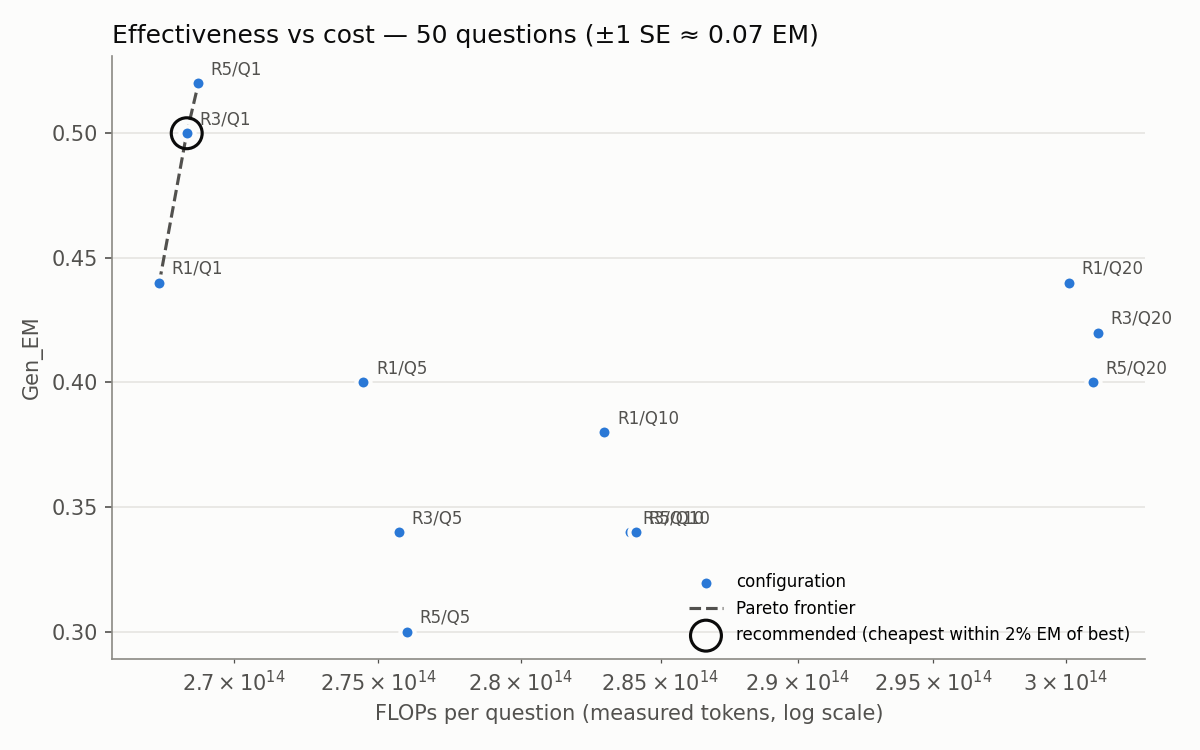

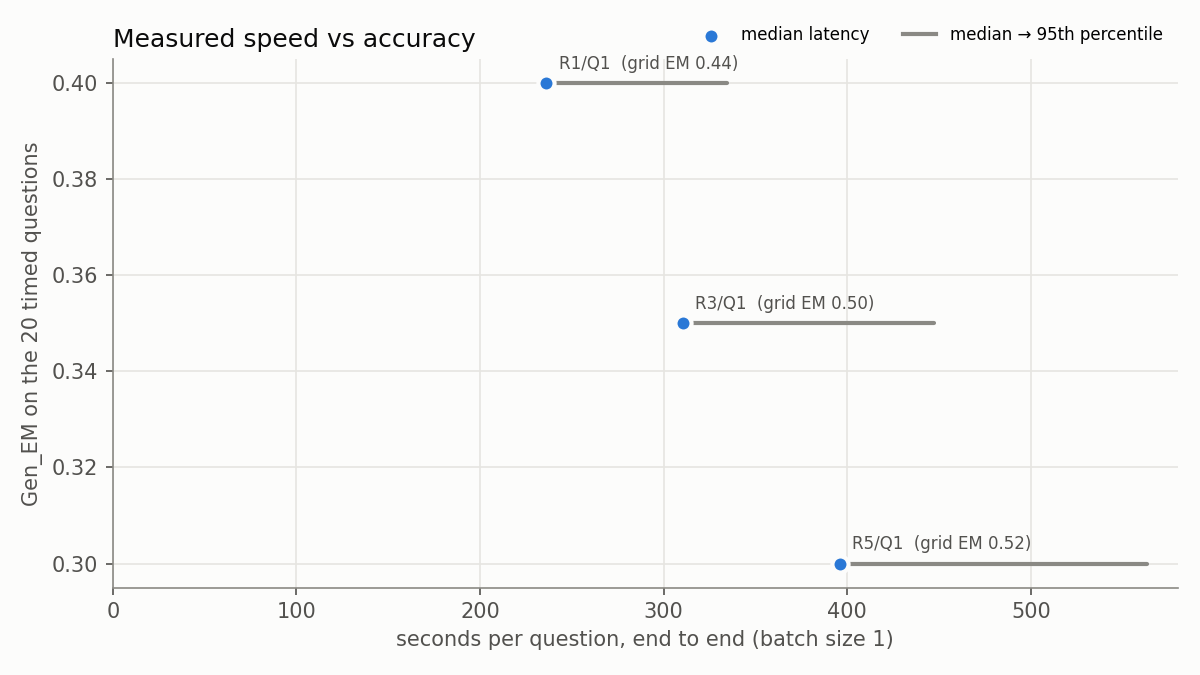

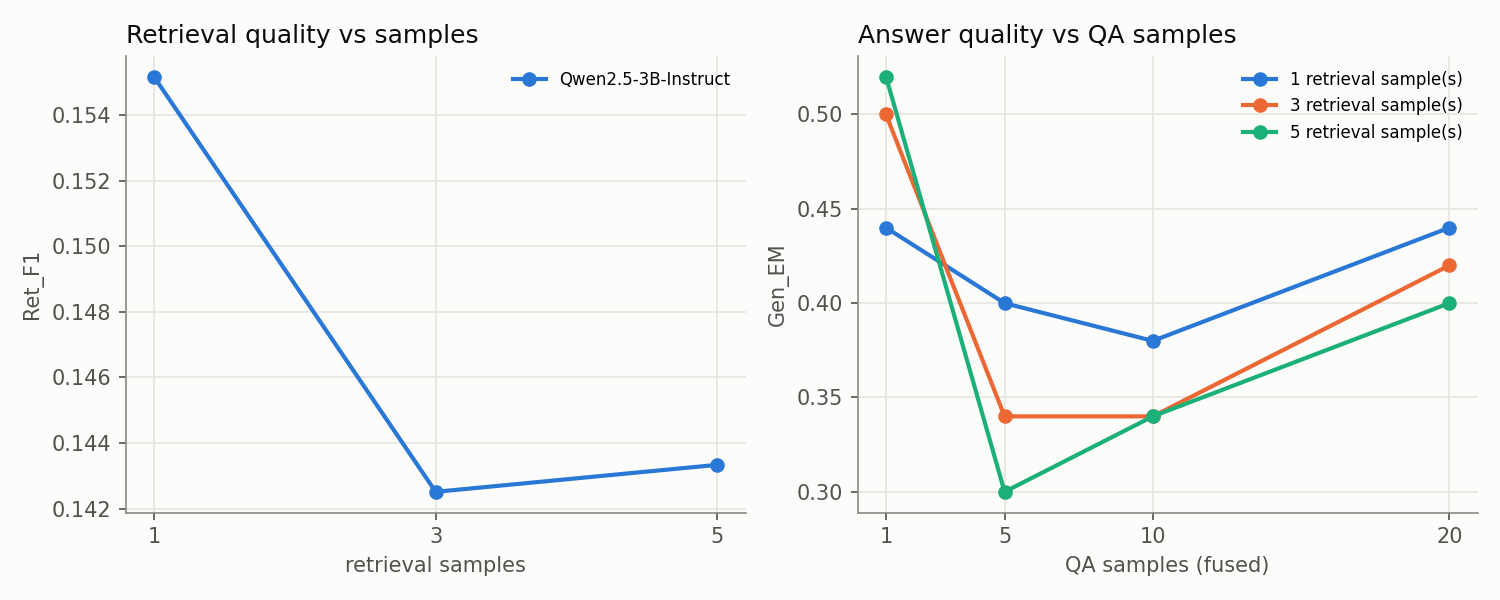

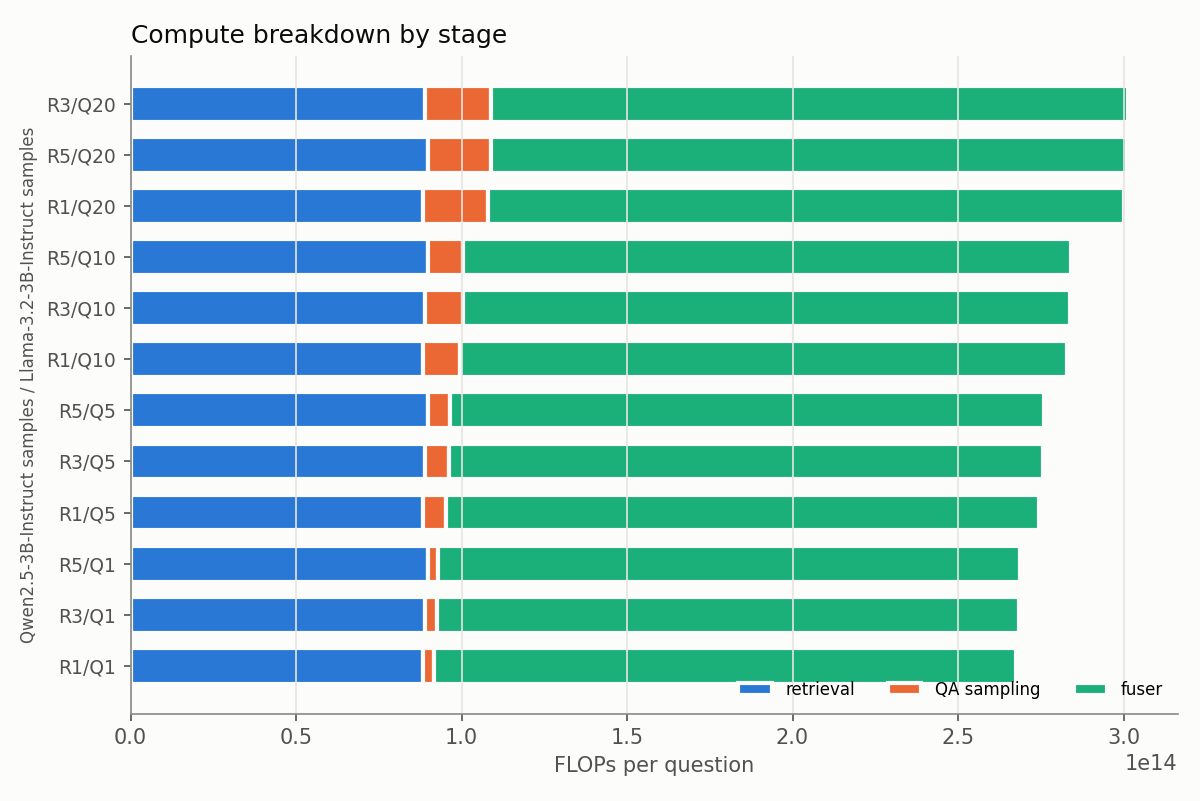

In [13]:
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
res = pd.read_csv(f"{RUN_DIR}/results/results_with_costs.csv")
display(res[["config", "Gen_EM", "Gen_F1", "Ret_F1", "flops_total", "budget_eq4", "budget_actual_total",
             "fuser_share_of_flops", "est_gpu_s", "latency_p50_s", "latency_p95_s", "questions_per_min",
             "on_pareto_front"]].round(3))
if os.path.exists(f"{RUN_DIR}/results/timed_latency.csv"):
    display(pd.read_csv(f"{RUN_DIR}/results/timed_latency.csv").round(3))
print("Wall-clock per notebook step (s):", {k: round(v) for k, v in TIMES.items()}, "| total:", round(sum(TIMES.values())))
for p in ["pareto_em_vs_flops.png", "latency_vs_em.png", "scaling_curves.png", "compute_breakdown.png"]:
    if os.path.exists(f"{RUN_DIR}/plots/{p}"):
        display(Image(f"{RUN_DIR}/plots/{p}"))

### Optional · Use this run as the lookup table for the AgentTTS search agent
The repo's `Environment` for `hotpotqa` reads `code_others/CSV_files/ret_then_gen_hotpotqa2.csv`. This cell copies the run's table there (columns match). Note that with one model per subtask the agent can only choose sample counts; add more models (e.g. Qwen2.5-1.5B, Llama-3.2-1B) to give it model-size choices.

In [14]:
EXPORT_TO_REPO = False
if EXPORT_TO_REPO:
    dst = f"{PROJECT_DIR}/AgentTTS/code_others/CSV_files"
    os.makedirs(dst, exist_ok=True)
    shutil.copy(f"{RUN_DIR}/results/ret_then_gen_hotpotqa_lookup.csv", f"{dst}/ret_then_gen_hotpotqa2.csv")
    print("exported to", dst)
config["finished"] = datetime.now(ZoneInfo("Asia/Singapore")).isoformat()
json.dump(config, open(f"{RUN_DIR}/config.json", "w"), indent=1)
!find "{RUN_DIR}" -maxdepth 2 -type f | sed "s|{RUN_DIR}/||" | sort

code/tts_runner.py
config.json
env.txt
logs/01_retrieve.log
logs/02_qa.log
logs/03_analyze.log
logs/04_timed_retrieve.log
logs/05_timed_qa.log
logs/06_analyze_final.log
logs/stage_times.json
plots/compute_breakdown.png
plots/latency_vs_em.png
plots/pareto_em_vs_flops.png
plots/scaling_curves.png
qa/Qwen2.5-3B-Instruct__Llama-3.2-3B-Instruct.jsonl
qa/Qwen2.5-3B-Instruct__Llama-3.2-3B-Instruct__qa_samples.jsonl
results/per_question.csv
results/results_with_costs.csv
results/ret_then_gen_hotpotqa_lookup.csv
results/summary.md
results/timed_configs.json
results/timed_latency.csv
results/timed_per_question.csv
retrieval/Qwen2.5-3B-Instruct.jsonl
stages/qa__Qwen2.5-3B-Instruct__Llama-3.2-3B-Instruct__1790497384.json
stages/retrieve__Qwen2.5-3B-Instruct__1790477222.json
stages/timed_qa__1790516866.json
stages/timed_retrieve__1790504949.json
timed/qa.jsonl
timed/retrieval.jsonl
